# Assignment #3

# 1. K-means from scratch (50 points)

Code up the K-means algorithm. To test your code, sample from the three bivariate Gaussian distributions provided below and find three clusters from this sampled data. To initialize your algorihtm, you may use the initial centroids defined below. After predicting the cluster to which each data point belongs, make a scatter plot similar to the one shown below. For consistency, set the random seed to 1 before sampling from the three bivariate Gaussian distributions.

* Bivariate Gaussians
$$\mathbf{\mu_1} = \begin{bmatrix}
3.0\\
1.0\\
\end{bmatrix}$$

$$\mathbf{\mu_2} = \begin{bmatrix}
-1.0\\
3.0\\
\end{bmatrix}$$

$$\mathbf{\mu_2} = \begin{bmatrix}
-5.0\\
2.0\\
\end{bmatrix}$$

$$\mathbf{\Sigma_1} = \mathbf{\Sigma_2} = \mathbf{\Sigma_3}\begin{bmatrix}
0.9&0.3\\
0.3&0.9\\
\end{bmatrix}$$

* Initial centroids:
$$\mathbf{c_1} = \begin{bmatrix}
0.4\\
0.3\\
\end{bmatrix}$$

$$\mathbf{c_2} = \begin{bmatrix}
0.1\\
0.4\\
\end{bmatrix}$$

$$\mathbf{c_2} = \begin{bmatrix}
-2.0\\
2.0\\
\end{bmatrix}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate data from three bivariate Gaussian distributions
np.random.seed(1)

mu1 = [3, 1]
mu2 = [-1, 3]
mu3 = [-5, 2]

cov = [[0.9, 0.3], [0.3, 0.9]]

X1 = np.random.multivariate_normal(mu1, cov, 100)
X2 = np.random.multivariate_normal(mu2, cov, 100)
X3 = np.random.multivariate_normal(mu3, cov, 100)

# Combine all samples into one dataset
X = np.vstack((X1, X2, X3))

# Step 2: Initialize the three centroids
centers = np.array([
    [0.4, 0.3],
    [0.1, 0.4],
    [-2.0, 2.0]
])

# Step 3: Implement K-means from scratch
for iteration in range(100):

    # Calculate squared Euclidean distances to each centroid
    distances = np.array([
        np.sum((X - c)**2, axis=1) for c in centers
    ]).T

    # Assign each point to its nearest centroid
    labels = np.argmin(distances, axis=1)

    # Update centroids using the mean of assigned points
    new_centers = np.array([
        X[labels == i].mean(axis=0) if np.any(labels == i)
        else centers[i]
        for i in range(3)
    ])

    # Stop if the centroids no longer change
    if np.allclose(centers, new_centers):
        centers = new_centers
        break

    centers = new_centers

# Step 4: Assign final cluster labels
distances = np.array([
    np.sum((X - c)**2, axis=1) for c in centers
]).T

labels = np.argmin(distances, axis=1)

# Step 5: Plot the clustering results
plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(X[labels == i, 0],
                X[labels == i, 1],
                label=f'Cluster {i+1}',
                alpha=0.6)

# Mark the final centroids
plt.scatter(centers[:, 0], centers[:, 1],
            c='black', marker='X', s=200,
            label='Centroids')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('K-means Clustering (K=3)')
plt.legend()
plt.grid(True)
plt.show()

# Print the final centroids and number of iterations
print("Final centroids:")
print(centers)
print("Number of iterations:", iteration + 1)

<Figure size 800x600 with 1 Axes>

Final centroids:
[[ 2.824456    0.84653064]
 [-1.02173212  3.11381515]
 [-5.17750158  2.033979  ]]
Number of iterations: 6


# 2. Predicting soil taxonomy (50 pts)

In the United States, soils are classified using the [USDA soil taxonomy](https://www.nrcs.usda.gov/Internet/FSE_DOCUMENTS/nrcs142p2_051232.pdf). Within the USDA soil taxonomy, the most general level is the taxonomic order. In this problem we will be using a suite of decision-tree based classification algorithms to create spatial maps of taxonomic order over western Illinois. The point observations come from the [NASIS database](https://www.nrcs.usda.gov/wps/portal/nrcs/detail/soils/survey/tools/?cid=nrcs142p2_053552) while the environmental predictors come from Sentinel 2, the National Elevation Data, and the National Land Cover database.

All the data has already been subsetted and preprocessed and are compiled in the following NetCDF file `/data/HW/HW3.nc`. The file is split into two groups: predictors and observations. The predictors group contains a set of 1 arcsec maps for the domain and the observations group contains the in-situ taxonomic order observations with their associated geographic coordinates. Although not required, we recommend using xarray to read in these data. 

**A.** Read in and create maps of all the predictors. Describe any apparent discrepancies in spatial resolution between the maps.

**B.** Read in the in-situ observations and assemble the corresponding predictors for each site. Create the $\mathbf{X}$ array of predictors and the $\mathbf{y}$ array of observed taxonomic orders. Note that you will need to convert the taxonomic order names to integers.

**C.** Use the validation set approach to divide your data into training and test datasets. The training dataset should 20% of the data. Then fit a Decision tree using the training data and evaluate its accuracy for both the training and test datasets. Explain the differences in accuracy when evaluating the training and test datasets. To ensure reproduceability, when initializing the decision tree, set the random_state to 1.

**D.** Using  all the site data, perform a 10-fold cross validation of the decision tree and compare the results to the previous exercise. Set random_state to 1 and set shuffle to True.

**E.** Setting the number of decision trees to 100, perform a 10-fold cross validation using Bagging, Random Forests, Gradient Boosting, and Multilayer Perceptrons (ANNs). Discuss how the results of these different ensemble methods vary amongst themselves. Also compare the results to those obtained from a single decision tree. Remember to set random_state to 1.

**F.** Using 100 trees, fit a Random Forest to the entire sites dataset and report the out of bag score. Compare that result to that obtained from the cross validation. Explain what the out of bag score is and how it can be more useful than cross validation. Remember to set random_state to 1.

**G.** Starting from 10 to 100 decision trees per Random Forest, determine the optimal number of decision trees. 

**H.** After fitting a random forest with 100 trees, plot a map of the entire region of the predicted taxonomy order.

**I.** Use Principal Component Analysis (PCA) to determine a reduced number of covariates. The exact number of features that you use from PCA is not as important as much as explaining why you use the result that you use. Fit and evaluate the Random Forest fit from the corresponding principal components.

In [2]:
import xarray as xr

file = "/data/HW/HW3.nc"

predictors = xr.open_dataset(file, group="predictors")
observations = xr.open_dataset(file, group="observations")

print(predictors)
print(observations)


<xarray.Dataset>
Dimensions:              (lat: 1080, lon: 1080)
Coordinates:
  * lat                  (lat) float64 39.85 39.85 39.85 ... 40.15 40.15 40.15
  * lon                  (lon) float64 -90.65 -90.65 -90.65 ... -90.35 -90.35
Data variables:
    elevation            (lat, lon) float32 ...
    ndvi                 (lat, lon) float32 ...
    evi                  (lat, lon) float32 ...
    red                  (lat, lon) float32 ...
    green                (lat, lon) float32 ...
    blue                 (lat, lon) float32 ...
    tree_cover_fraction  (lat, lon) float32 ...
    gamma_uranium        (lat, lon) float32 ...
    gamma_thorium        (lat, lon) float32 ...
    gamma_potassium      (lat, lon) float32 ...
<xarray.Dataset>
Dimensions:          (site: 153)
Dimensions without coordinates: site
Data variables:
    lat              (site) float64 ...
    lon              (site) float64 ...
    taxonomic_order  (site) object ...


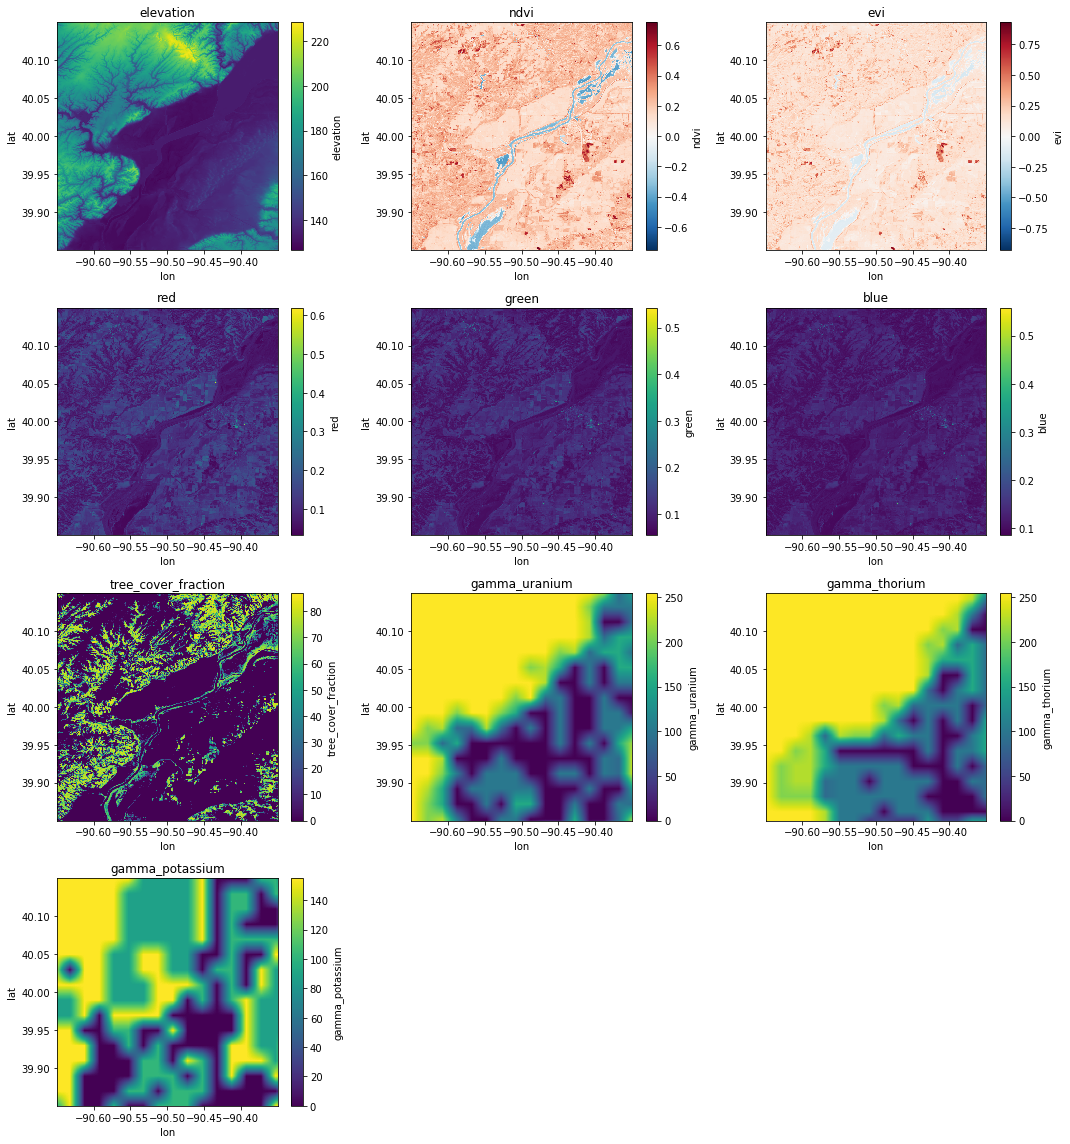

In [5]:
import matplotlib.pyplot as plt

# A: Plot all environmental predictor maps
features = list(predictors.data_vars)

fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

for i, name in enumerate(features):
    predictors[name].plot(ax=axes[i])
    axes[i].set_title(name)

# Hide unused subplots
for ax in axes[len(features):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
%matplotlib inline

In [7]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

# B: Read soil observation coordinates and classes
lat = observations["lat"].values
lon = observations["lon"].values
soil = observations["taxonomic_order"].values

features = list(predictors.data_vars)

# Remove sites with invalid coordinates or missing soil labels
soil_names = np.array([
    s.decode() if isinstance(s, bytes) else str(s)
    for s in soil
])

valid = (
    np.isfinite(lat) & np.isfinite(lon) &
    (lat >= predictors.lat.min().item()) &
    (lat <= predictors.lat.max().item()) &
    (lon >= predictors.lon.min().item()) &
    (lon <= predictors.lon.max().item()) &
    ~np.isin(np.char.strip(soil_names), ["", "nan", "None"])
)

# Find the nearest grid cell for each observation
sites = {
    "lat": xr.DataArray(lat[valid], dims="site"),
    "lon": xr.DataArray(lon[valid], dims="site")
}

# Create the predictor matrix X
X = np.column_stack([
    predictors[name].sel(sites, method="nearest").values
    for name in features
])

# Keep sites with at least one valid predictor
keep = np.isfinite(X).any(axis=1)
X = X[keep]

# Convert soil class names into integers
encoder = LabelEncoder()
y = encoder.fit_transform(soil_names[valid][keep])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Soil classes:", encoder.classes_)
print("Missing predictor values:", np.isnan(X).sum())

X shape: (152, 10)
y shape: (152,)
Soil classes: ['alfisols' 'entisols' 'inceptisols' 'mollisols']
Missing predictor values: 0


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# C: Split data into 20% training and 80% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.2, random_state=1
)

# Train the Decision Tree model
tree = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(random_state=1)
)

tree.fit(X_train, y_train)

# Evaluate model accuracy
train_acc = tree.score(X_train, y_train)
test_acc = tree.score(X_test, y_test)

print("Training accuracy:", train_acc)
print("Test accuracy:", test_acc)

Training accuracy: 1.0
Test accuracy: 0.5737704918032787


In [9]:
from sklearn.model_selection import KFold, cross_val_score

# D: Perform 10-fold cross-validation
cv = KFold(n_splits=10, shuffle=True, random_state=1)

scores = cross_val_score(
    tree, X, y, cv=cv, scoring="accuracy"
)

print("10-fold CV scores:", scores)
print("Mean CV accuracy:", scores.mean())
print("CV standard deviation:", scores.std())
print("Previous test accuracy:", test_acc)

10-fold CV scores: [0.625      0.5625     0.8        0.66666667 0.8        0.4
 0.73333333 0.4        0.8        0.66666667]
Mean CV accuracy: 0.6454166666666667
CV standard deviation: 0.1442467263252638
Previous test accuracy: 0.5737704918032787


In [11]:
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# E: Define the classification models
models = {
    "Bagging": BaggingClassifier(
        n_estimators=100, random_state=1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, random_state=1
    ),
    # ANN: Use the L-BFGS optimizer for a small dataset
     "ANN": MLPClassifier(
    hidden_layer_sizes=(100,),
    solver="lbfgs",
    max_iter=3000,
    random_state=1
)
}

# Compare the models using 10-fold cross-validation
results = {"Decision Tree": scores.mean()}

for name, model in models.items():

    if name == "ANN":
        clf = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            model
        )
    else:
        clf = make_pipeline(
            SimpleImputer(strategy="median"),
            model
        )

    cv_scores = cross_val_score(clf, X, y, cv=cv)
    results[name] = cv_scores.mean()

    print(name, ":", cv_scores.mean())

Bagging : 0.7170833333333333
Random Forest : 0.7704166666666665
Gradient Boosting : 0.76375
ANN : 0.6379166666666667


In [12]:
# F: Train Random Forest with 100 trees
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=1
)

# Fill missing values using the median
imputer = SimpleImputer(strategy="median")
X_clean = imputer.fit_transform(X)

# Fit the Random Forest
rf.fit(X_clean, y)

# Compare OOB and cross-validation accuracy
print("OOB score:", rf.oob_score_)
print("10-fold CV accuracy:", results["Random Forest"])

OOB score: 0.743421052631579
10-fold CV accuracy: 0.7704166666666665


10 trees: 0.74375
20 trees: 0.7308333333333333
30 trees: 0.7633333333333333
40 trees: 0.7508333333333332
50 trees: 0.7508333333333332
60 trees: 0.7575
70 trees: 0.7575
80 trees: 0.7441666666666666
90 trees: 0.7441666666666666
100 trees: 0.7704166666666665
Optimal number of trees: 100
Best CV accuracy: 0.7704166666666665


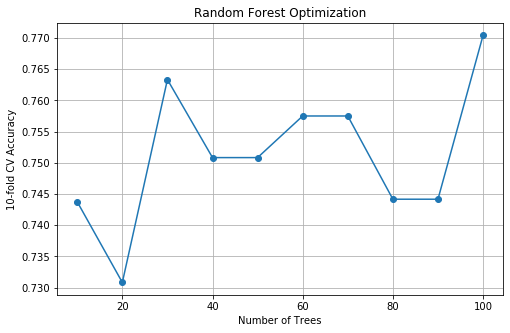

In [13]:
# G: Find the optimal number of trees
numbers = range(10, 101, 10)
accuracies = []

for n in numbers:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=n,
            random_state=1
        )
    )

    score = cross_val_score(
        model, X, y, cv=cv
    ).mean()

    accuracies.append(score)
    print(n, "trees:", score)

# Find the best number of trees
best_n = list(numbers)[np.argmax(accuracies)]

print("Optimal number of trees:", best_n)
print("Best CV accuracy:", max(accuracies))

# Plot model accuracy
plt.figure(figsize=(8, 5))
plt.plot(list(numbers), accuracies, marker="o")

plt.xlabel("Number of Trees")
plt.ylabel("10-fold CV Accuracy")
plt.title("Random Forest Optimization")
plt.grid(True)
plt.show()

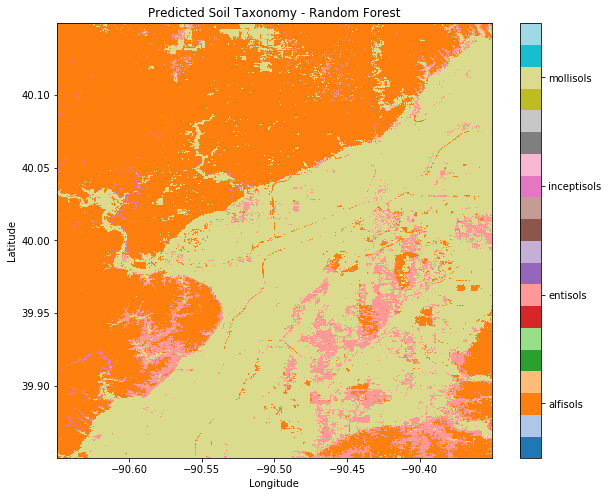

In [14]:
# H: Prepare predictor values for the entire region
grid_X = np.column_stack([
    predictors[name].values.ravel()
    for name in features
])

# Replace infinite values with NaN
grid_X[~np.isfinite(grid_X)] = np.nan

# Identify valid grid cells
valid_grid = np.isfinite(grid_X).any(axis=1)
prediction = np.full(len(grid_X), np.nan)

# Predict soil taxonomy using the trained Random Forest
indices = np.where(valid_grid)[0]

for start in range(0, len(indices), 30000):
    idx = indices[start:start + 30000]

    # Apply the same imputer used during training
    X_batch = imputer.transform(grid_X[idx])

    prediction[idx] = rf.predict(X_batch)

# Reshape the predictions into a spatial map
soil_map = prediction.reshape(
    len(predictors.lat),
    len(predictors.lon)
)

# Plot the predicted soil taxonomy map
plt.figure(figsize=(10, 8))

plt.imshow(
    soil_map,
    origin="lower",
    extent=[
        predictors.lon.min().item(),
        predictors.lon.max().item(),
        predictors.lat.min().item(),
        predictors.lat.max().item()
    ],
    cmap="tab20",
    vmin=-0.5,
    vmax=len(encoder.classes_) - 0.5
)

# Display soil taxonomy class names
cbar = plt.colorbar(ticks=range(len(encoder.classes_)))
cbar.ax.set_yticklabels(encoder.classes_)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Predicted Soil Taxonomy - Random Forest")
plt.show()

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# I: Reduce the number of features using PCA
pca_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=0.95),
    RandomForestClassifier(
        n_estimators=100,
        random_state=1
    )
)

# Evaluate PCA + Random Forest using 10-fold cross-validation
pca_scores = cross_val_score(
    pca_model, X, y, cv=cv, scoring="accuracy"
)

# Fit PCA and Random Forest on the full dataset
pca_model.fit(X, y)

# Get the number of selected principal components
n = pca_model.named_steps["pca"].n_components_

# Compare model accuracy before and after PCA
print("Original number of features:", X.shape[1])
print("Selected principal components:", n)
print("PCA + RF accuracy:", pca_scores.mean())
print("Original RF accuracy:", results["Random Forest"])

Original number of features: 10
Selected principal components: 6
PCA + RF accuracy: 0.7104166666666666
Original RF accuracy: 0.7704166666666665
